# 0 Load packages

In [19]:
import os
import torch
from torch.utils.data import DataLoader, ConcatDataset

import yaml
import warnings
warnings.filterwarnings("ignore")

os.environ["CUDA_VISIBLE_DEVICES"] = "3"  # "1"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[Debug] Using device: {device}")
print(f"[Debug] CUDA_VISIBLE_DEVICES = {os.environ['CUDA_VISIBLE_DEVICES']}")
print(f"[Debug] torch.cuda.current_device() = {torch.cuda.current_device()}")
print(f"[Debug] torch.cuda.get_device_name(0) = {torch.cuda.get_device_name(0)}")

from functions.Dataset import MyDataset
from functions.TranSyn_evaluate import direct_inference

from functions.TranSynAttention import TranSynAttention
from functions.ModelScaffold import build_backbone
from functions.DyPositionTransformer import DyPositionTransformer

[Debug] Using device: cuda
[Debug] CUDA_VISIBLE_DEVICES = 3
[Debug] torch.cuda.current_device() = 0
[Debug] torch.cuda.get_device_name(0) = NVIDIA GeForce RTX 3090


# 1 Build model

In [ ]:
# config
model_combo = "GPN_CaLM_NewBio"
weight_path = f"./result/section_2/GPN_CaLM_NewBio/best_model.pt"
with open('./config/config.yaml', 'r', encoding='utf-8') as file:
	config = yaml.safe_load(file)
	spc_config = config[model_combo]

print("[INFO] Building model...")
## DNA submodule
tsa_dna_module = build_backbone(name="ResNet1D", seq_len=129, embed_dim=768)
## RNA submodule
tsa_rna_module = DyPositionTransformer(
						input_dim=768,
						num_layers=4,
						d_model=256,
						num_heads=4,
						dff=512,
						dropout_rate=0.1,
						head_hidden=128,
				).to(device) 
## bio submodule
tsa_bio_module = build_backbone(name="MLP", embed_dim=49, output_dim=spc_config['BIO_HIDDEN']).to(device) 
my_model = TranSynAttention(
			dna_module = tsa_dna_module,
			rna_module = tsa_rna_module,
			bio_module = tsa_bio_module,
			hidden_layer = spc_config['HEAD_HIDDEN'],
			dropout = spc_config['DROPOUT_RATE']
		).to(device) 

## load weight
my_model.load_state_dict(torch.load(weight_path, map_location='cpu'))

[INFO] Building model...


<All keys matched successfully>

# 2 Inference

In [ ]:
print("[INFO] Loading data...")
test_data = MyDataset(data_path=f"./result/section_5/actionable.feature.pth", label=-1) # Unknown label
test_loader = DataLoader(test_data, batch_size=32, shuffle=False, num_workers=4)

[INFO] Loading data...


# 3 Enrichment analysis

In [ ]:
import pandas as pd

df = pd.read_csv("./result/section_5/ACMG.actionable.genes.GRCh38.vcf", sep='\t')

## 🔹 Figure 5A

In [ ]:
# Plotting
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter

values = df['pred_prob'].dropna().values

# Segmentation
low_vals = values[values <= 0.1]
mid_vals = values[(values > 0.1) & (values < 0.9)]
high_vals = values[values >= 0.9]

# Counts
n_low = len(low_vals)
n_mid = len(mid_vals)
n_high = len(high_vals)

n_low_str = f"{n_low:,}"
n_mid_str = f"{n_mid:,}"
n_high_str = f"{n_high:,}"

# Plotting
fig, ax = plt.subplots(figsize=(6.2, 5))
bins = np.linspace(0, 1, 50)
ax.hist(mid_vals, bins=bins, color="#ebe3dd",
        label=f'Indeterminate (n={n_mid_str})')
ax.hist(low_vals, bins=bins, color='#47a2bb',
        label=f'Predicted benign (n={n_low_str})')
ax.hist(high_vals, bins=bins, color='#e24636',
        label=f'Predicted pathogenic (n={n_high_str})')

# Threshold lines
ax.axvline(0.1, linestyle='--', color='gray', linewidth=1)
ax.axvline(0.9, linestyle='--', color='gray', linewidth=1)

# Scientific notation
formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((0, 0))  # Force scientific notation
ax.yaxis.set_major_formatter(formatter)
# Control exponent display position
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax.yaxis.get_offset_text().set_fontsize(12)

# Styling
ax.set_xlabel('TranSyn score', fontsize=13)
ax.set_ylabel('Count', fontsize=13)
plt.tick_params(axis='both', labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(0.5)
    spine.set_color('#333')

from matplotlib.lines import Line2D
markersize = 12
legend_elements = [
    Line2D([0], [0],
           marker='o',
           color='none',
           label=f'Indeterminate (n={n_mid_str})',
           markerfacecolor='#ebe3dd',
           markeredgecolor='none',
           markersize=markersize),

    Line2D([0], [0],
           marker='o',
           color='none',
           label=f'Predicted benign (n={n_low_str})',
           markerfacecolor='#47a2bb',
           markeredgecolor='none',
           markersize=markersize),

    Line2D([0], [0],
           marker='o',
           color='none',
           label=f'Predicted pathogenic (n={n_high_str})',
           markerfacecolor='#e24636',
           markeredgecolor='none',
           markersize=markersize),
]
ax.legend(handles=legend_elements, frameon=False, fontsize=12)

plt.tight_layout()
plt.show()

## 🔹 Figure 5B

### (A) Statistic

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import binomtest
from statsmodels.stats.multitest import multipletests

def classify(p):
    """Map categories based on score"""
    if p >= 0.9:
        return 'pathogenic'
    elif p <= 0.1:
        return 'benign'
    else:
        return 'indeterminate'

df = df.copy()
df['label'] = df['pred_prob'].apply(classify)  # Assign categories

# Gene-level statistics
summary = (
    df
    .groupby(['gene', 'label'])
    .size()
    .unstack(fill_value=0)
)
for col in ['pathogenic', 'benign', 'indeterminate']:
    if col not in summary.columns:
        summary[col] = 0
summary['total'] = summary.sum(axis=1)

# Sample size filtering (at least 20 samples)
min_n = 20
summary = summary[summary['total'] >= min_n].copy()

# Calculate global proportions
global_rates = df['label'].value_counts(normalize=True)
p_path = global_rates.get('pathogenic', 0)
p_benign = global_rates.get('benign', 0)
p_indet = global_rates.get('indeterminate', 0)

# Binomial test
def binom_pval(k, n, p0, alternative):
    if n == 0:
        return np.nan
    k = int(k)
    n = int(n)
    return binomtest(k, n, p0, alternative=alternative).pvalue

summary['p_path'] = summary.apply(
    lambda r: binom_pval(r['pathogenic'], r['total'], p_path, 'greater'), axis=1
)
summary['p_benign'] = summary.apply(
    lambda r: binom_pval(r['benign'], r['total'], p_benign, 'greater'), axis=1
)
summary['p_indet'] = summary.apply(
    lambda r: binom_pval(r['indeterminate'], r['total'], p_indet, 'greater'), axis=1
)

# Multiple testing correction
for col in ['p_path', 'p_benign', 'p_indet']:
    mask = summary[col].notna()
    summary.loc[mask, col + '_adj'] = multipletests(
        summary.loc[mask, col],
        method='fdr_bh'
    )[1]

# Proportions
summary['path_ratio'] = summary['pathogenic'] / summary['total']
summary['benign_ratio'] = summary['benign'] / summary['total']
summary['indet_ratio'] = summary['indeterminate'] / summary['total']

### (B) Plot

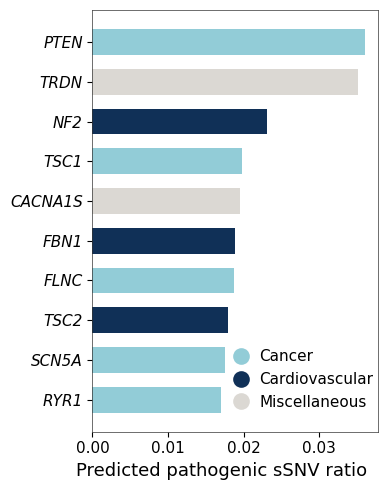

In [ ]:
import matplotlib.pyplot as plt

# ACMG gene information
acmg_actions = pd.read_csv("./result/section_5/ACMG_actions.csv", usecols=['Gene', 'Phenotype Category'])

# Display top 20 genes
top_n = 20
df_plot = summary[
    summary['p_path_adj'] < 0.05
].sort_values('path_ratio', ascending=False).head(top_n)

# Merge phenotype information
df_plot = df_plot.reset_index()  # Move gene index to column
df_plot = df_plot.merge(acmg_actions, left_on='gene', right_on='Gene', how='left')
df_plot = df_plot.drop('Gene', axis=1)
df_plot['Phenotype Category'] = df_plot['Phenotype Category'].fillna('Unknown')
df_plot = df_plot.set_index('gene')

# Plot colors and categories
categories = df_plot['Phenotype Category'].unique()
# colors = ['#e24636', '#47a2bb', '#e1ddd6']
colors = ['#92ccd7', '#103057', "#dbd8d3"]
category_colors = {
    'Cancer': '#92ccd7',
    'Cardiovascular': '#103057',
    'Miscellaneous': '#dbd8d3'}

# Plotting
plt.figure(figsize=(4, 5))
plt.barh(
    df_plot.index[::-1],
    df_plot['path_ratio'][::-1],
    color=colors,
    height=0.65
)

# X and Y axis design
plt.xlabel('Predicted pathogenic sSNV ratio', fontsize=13, x=0.45)
plt.yticks(fontstyle='italic')

# Legend
from matplotlib.lines import Line2D
markersize = 12
legend_elements = [
    Line2D([0], [0],
           marker='o',
           color='none',
           label='Cancer',
           markerfacecolor='#92ccd7',
           markeredgecolor='none',
           markersize=markersize),

    Line2D([0], [0],
           marker='o',
           color='none',
           label='Cardiovascular',
           markerfacecolor='#103057',
           markeredgecolor='none',
           markersize=markersize),

    Line2D([0], [0],
           marker='o',
           color='none',
           label='Miscellaneous',
           markerfacecolor='#dbd8d3',
           markeredgecolor='none',
           markersize=markersize),
]
plt.legend(handles=legend_elements, 
           frameon=False, 
           fontsize=11, 
           loc='lower right', 
           handletextpad=0.2,
           bbox_to_anchor=[1.03, 0.02])

# Plot borders
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(.5)
    spine.set_color('#333')
plt.tick_params(axis='both', labelsize=11)

plt.tight_layout()
plt.show()

## 🔹 Figure 5C 5D

### (A) Statistic-global level

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import fisher_exact, chi2_contingency

# 1. Filter data
df_mi = df[df['label'].isin(['benign', 'pathogenic'])].copy()

# 2. Create binary variable
df_mi['binding'] = df_mi['miRNA binding'].notna().astype(int)

# 3. Create contingency table
table = pd.crosstab(df_mi['label'], df_mi['binding'])

# Ensure consistent column order
table = table.reindex(index=['benign', 'pathogenic'], columns=[0, 1], fill_value=0)
print(table)

# 4. Fisher exact test
oddsratio, p_value = fisher_exact(table.values)

print("Fisher p-value:", p_value)
print("Odds ratio:", oddsratio)

# 5. Chi-square test
chi2, p_chi2, _, _ = chi2_contingency(table.values)
print("Chi-square p-value:", p_chi2)

binding         0      1
label                   
benign      43384  10564
pathogenic   1847    220
Fisher p-value: 4.002696467215873e-27
Odds ratio: 0.48916681204946283
Chi-square p-value: 6.341866265160693e-24


### (B) Plot-global level

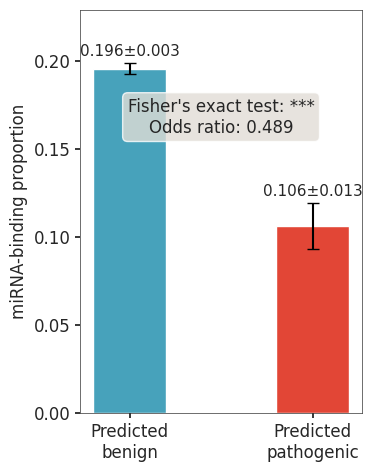

In [ ]:
import numpy as np

def proportion_ci(k, n):
    """Calculate confidence interval for proportion"""
    p = k / n
    se = np.sqrt(p * (1 - p) / n)
    return p, 1.96 * se

# Calculate proportions and confidence intervals
b_p, b_err = proportion_ci(10564, 43382 + 10564)
p_p, p_err = proportion_ci(220, 1847 + 220)

plt.figure(figsize=(4, 5))

# Plot bar chart
bars = plt.bar(['Benign', 'Pathogenic'],
               [b_p, p_p],
               yerr=[b_err, p_err],
               capsize=4,
               width=0.4,
               color=['#47a2bb', '#e24636'])

# Statistical test results for annotation
fisher_p = 4.0048604813542526e-27
chi2_p = 6.29826312909e-24
odds_ratio = 0.489144261486488

# Format p-value for display
def get_significance_stars(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

# Add text annotation on the plot
x_positions = [0, 1]  # X coordinates of bars
y_max = max(b_p + b_err, p_p + p_err)

# Add statistical test results
stat_text = (f"Fisher's exact test: {get_significance_stars(fisher_p)}\n"
             # f"Chi-square test: {get_significance_stars(chi2_p)}\n"
             f"Odds ratio: {odds_ratio:.3f}")

plt.text(0.5, y_max * 0.9, stat_text, 
         transform=plt.gca().transData,
         ha='center', va='top',
         bbox=dict(boxstyle='round', facecolor='#e1ddd6', alpha=0.8),
         fontsize=12)

# Annotate specific values above the bars
for i, (p, err) in enumerate(zip([b_p, p_p], [b_err, p_err])):
    plt.text(i, p + err + 0.002, f'{p:.3f}±{err:.3f}',
             ha='center', va='bottom', fontsize=11)

# Y-axis tick interval of 0.05, keep two decimal places
plt.gca().yaxis.set_major_locator(plt.MultipleLocator(0.05))
plt.gca().yaxis.set_major_formatter(plt.FormatStrFormatter('%.2f'))

# Set y-axis range to leave space for text
plt.ylim(0, y_max * 1.15)

# Rename x-axis labels
plt.gca().set_xticklabels(['Predicted\nbenign', 'Predicted\npathogenic'])
plt.tick_params(axis='both', labelsize=12)

# Plot borders
for spine in plt.gca().spines.values():
    spine.set_linewidth(0.5)
    spine.set_color('#333')

plt.ylabel('miRNA-binding proportion', fontsize=12)
plt.tight_layout()
plt.show()

### (C) Statistic-gene level

In [ ]:
import pandas as pd
import numpy as np

df_gene_mi = df_mi.copy()
df_gene_mi["label_bin"] = (df_gene_mi["label"] == "pathogenic").astype(int)

def compute_or(g):
    table = pd.crosstab(g["binding"], g["label_bin"])
    
    # Ensure 2x2 structure
    table = table.reindex(index=[0,1], columns=[0,1], fill_value=0)
    
    # Add 1 smoothing to avoid zeros
    a = table.loc[1,1] + 1   # binding=1 & pathogenic
    b = table.loc[1,0] + 1   # binding=1 & benign
    c = table.loc[0,1] + 1   # binding=0 & pathogenic
    d = table.loc[0,0] + 1   # binding=0 & benign
    
    or_value = (a / b) / (c / d)
    return pd.Series({"OR": or_value, "n": len(g)})

from scipy.stats import fisher_exact

def compute_stats(g):
    table = pd.crosstab(g["binding"], g["label_bin"])
    table = table.reindex(index=[0,1], columns=[0,1], fill_value=0)

    oddsratio, p = fisher_exact(table)

    return pd.Series({
        "OR": oddsratio,
        "log2OR": np.log2(oddsratio) if oddsratio > 0 else np.nan,
        "p": p,
        "n": len(g),
        "binding_n": table.loc[1].sum()
    })

gene_stats = (
    df_gene_mi
    .groupby("gene")
    .apply(compute_stats)
    .reset_index()
)
gene_stats = gene_stats[
    gene_stats["binding_n"] > 0
]

gene_stats.sort_values("log2OR")

,gene,OR,log2OR,p,n,binding_n
13,CALM2,0.078571,-3.669851,0.016535,45.0,29.0
49,PRKAG2,0.118615,-3.075645,0.012743,402.0,106.0
34,MLH1,0.155861,-2.681671,0.040352,808.0,172.0
53,RET,0.160877,-2.635969,0.047624,810.0,124.0
12,CALM1,0.166667,-2.584963,0.129354,53.0,44.0
...,...,...,...,...,...,...
72,TP53,0.000000,NaN,0.014487,294.0,75.0
73,TPM1,0.000000,NaN,1.000000,91.0,7.0
74,TRDN,0.000000,NaN,0.148430,381.0,19.0
77,TTR,0.000000,NaN,0.320721,132.0,38.0


### (D) Plot-gene level

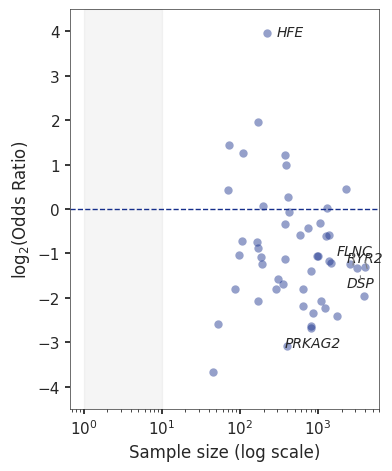

In [ ]:
from adjustText import adjust_text
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from adjustText import adjust_text

# ==========================
# preprocess
# ==========================

dfp = gene_stats.copy()

# Remove non-estimable OR
dfp = dfp.replace([np.inf, -np.inf], np.nan)
dfp = dfp.dropna(subset=["OR"])

# Remove genes with no binding (recommended)
if "binding_n" in dfp.columns:
    dfp = dfp[dfp["binding_n"] > 0]

# Avoid log2(0)
dfp = dfp[dfp["OR"] > 0]

# log2(OR)
dfp["log2OR"] = np.log2(dfp["OR"])

# Point size (sqrt scaling is more stable)
# dfp["point_size"] = np.sqrt(dfp["n"]) * 8
dfp["point_size"] = dfp["n"]

# ==========================
# choose genes to annotate
# ==========================

if "p" in dfp.columns:
    # Recommended: effect size + significance
    extreme = dfp[
        (np.abs(dfp["log2OR"]) > 1) &   # OR > 2 or < 0.5
        (dfp["p"] < 0.05) &
        (dfp["n"] >= 10)
    ]
else:
    # fallback: effect size + n only
    extreme = dfp[
        (np.abs(dfp["log2OR"]) > 2) &   # OR > 4
        (dfp["n"] >= 10)
    ]

# ==========================
# plot
# ==========================

fig, ax = plt.subplots(figsize=(4.2, 5))

# Small sample region shading
ax.axvspan(
    1,
    10,
    alpha=0.08,
    color='gray'
)

# Scatter plot
scatter = ax.scatter(
    dfp["n"],
    dfp["log2OR"],
    # s=dfp["point_size"],
    alpha=0.45,
    color="#152e8b",
    linewidth=0
)

# Baseline
ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
    color="#152e8b"
)

# ==========================
# gene annotation
# ==========================
extreme = extreme.sort_values(by='p')
extreme = extreme.head(5)  # Show top 5 based on p-value
texts = []

for _, r in extreme.iterrows():
    texts.append(
        ax.text(
            r["n"] * 1.09,          # Offset in x direction first
            r["log2OR"] - 0.1,      # Offset in y direction first
            r["gene"],
            fontsize=10,
            fontstyle='italic'
        )
    )

adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(
        arrowstyle='-',
        color='gray',
        lw=0.8,
        alpha=1
    ),
    expand_text=(1.5, 1.5),      # Increase space around text
    expand_points=(1.5, 1.5),    # Increase space around points
    force_text=(1.0, 1.0),       # Repulsion force between texts
    force_points=(0.3, 0.3),     # Attraction force from points to texts
    lim=500,                      # Increase iteration count
    precision=0.01,
    autoalign='xy',              # Auto alignment
    only_move={'points':'xy', 'text':'xy'}  # Allow movement
)

# ==========================
# axis settings
# ==========================

# log x-axis
ax.set_xscale("log")

# auto ylim
v = np.nanpercentile(
    np.abs(dfp["log2OR"]),
    99
)

ax.set_ylim(
    -v * 1.1,
    v * 1.1
)

ax.set_xlabel(
    "Sample size (log scale)",
    fontsize=12
)

ax.set_ylabel(
    "log$_2$(Odds Ratio)",
    fontsize=12
)

ax.tick_params(
    axis='both',
    labelsize=11
)

# border style
for spine in ax.spines.values():
    spine.set_linewidth(0.5)
    spine.set_color('#333333')
plt.ylim(-4.5, 4.5)
plt.tight_layout()

plt.show()

## 🔹 Figure 5E 5F

### (A) Statistic-global level

In [ ]:
from scipy.stats import mannwhitneyu


df_mrna = df[df['label'].isin(['benign', 'pathogenic'])].copy()
benign_vals = df_mrna[df_mrna['label'] == 'benign']['delta_MFE'].dropna()
path_vals = df_mrna[df_mrna['label'] == 'pathogenic']['delta_MFE'].dropna()

# Statistical test
stat, p_value = mannwhitneyu(
    benign_vals,
    path_vals,
    alternative='two-sided'
)

print("Mann-Whitney p:", p_value)

# effect size
import numpy as np
def cliffs_delta(x, y):
    """
    # If delta > 0: benign group has higher MFE than pathogenic group
    # If delta < 0: pathogenic group has higher MFE than benign group
    # Larger |delta| indicates more pronounced difference between the two groups
    """
    x = np.array(x)
    y = np.array(y)
    return (np.sum(x[:, None] > y) - np.sum(x[:, None] < y)) / (len(x) * len(y))

delta = cliffs_delta(benign_vals.values, path_vals.values)
print("Cliff's delta:", delta)

Mann-Whitney p: 1.4056843881655648e-14
Cliff's delta: -0.09926190592391385


### (B) Plot-global level

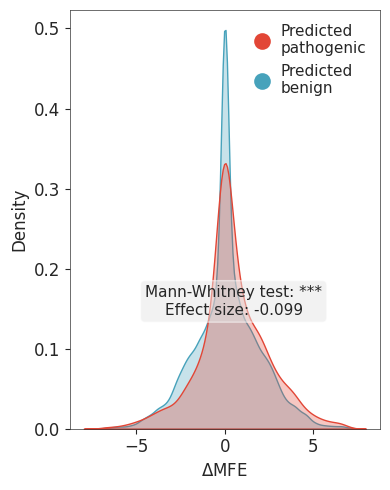

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 5))

# Plot KDE
sns.kdeplot(benign_vals, label='Predicted\nbenign', color='#47a2bb', fill=True, alpha=0.3)
sns.kdeplot(path_vals, label='Predicted\npathogenic', color='#e24636', fill=True, alpha=0.3)

# Set x and y axes
plt.tick_params(axis='both', labelsize=12)
plt.xlabel(f'$\Delta$MFE', fontsize=12)
plt.ylabel('Density', fontsize=12)

# Set legend
from matplotlib.lines import Line2D
markersize = 12
legend_elements = [
    Line2D([0], [0],
           marker='o',
           color='none',
           label='Predicted\npathogenic',
           markerfacecolor='#e24636',
           markeredgecolor='none',
           markersize=markersize),

    Line2D([0], [0],
           marker='o',
           color='none',
           label='Predicted\nbenign',
           markerfacecolor='#47a2bb',
           markeredgecolor='none',
           markersize=markersize),
]
plt.legend(handles=legend_elements, 
           frameon=False, 
           fontsize=11, 
           loc='upper right', 
           handletextpad=0.2,)

# Format p-value display
p = 1.4056843881655648e-14
effect_size = -0.09926190592391385

def get_significance_stars(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

# Add statistical test results
stat_text = (f"Mann-Whitney test: {get_significance_stars(p)}\n"
             f"Effect size: {effect_size:.3f}")

# Get current y-axis limit for text positioning
y_max = plt.gca().get_ylim()[1]

plt.text(0.5, y_max * 0.9, stat_text, 
         transform=plt.gca().transData,
         ha='center', va='top',
         bbox=dict(boxstyle='round', facecolor="#e6e6e6", alpha=0.5),
         fontsize=11)

# Set border thickness
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(.5)
    spine.set_color('#333')

plt.tight_layout()
plt.show()

### (C) Statistic-gene level


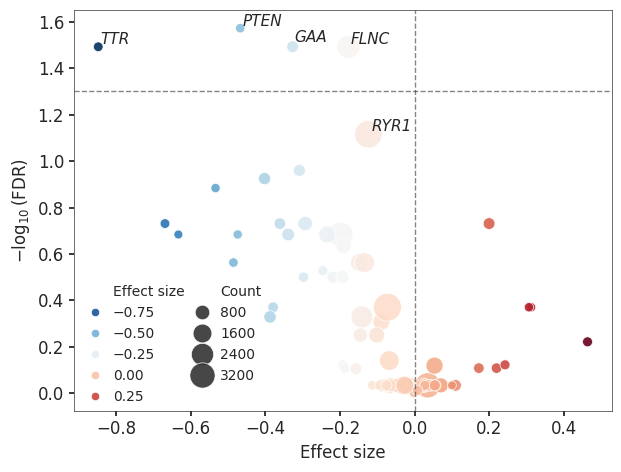

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from adjustText import adjust_text


def cliffs_delta(x, y):
    """
    # If delta > 0: benign group has higher MFE than pathogenic group
    # If delta < 0: pathogenic group has higher MFE than benign group
    # Larger |delta| indicates more pronounced difference between the two groups
    """
    x = np.array(x)
    y = np.array(y)
    if len(x) == 0 or len(y) == 0:
        return np.nan
    return (np.sum(x[:, None] > y) - np.sum(x[:, None] < y)) / (len(x) * len(y))

# Gene-level statistics
def calc_stats(g):
    benign = g[g['label'] == 'benign']['delta_MFE'].dropna()
    path = g[g['label'] == 'pathogenic']['delta_MFE'].dropna()
    if len(benign) < 2 or len(path) < 2:
        return pd.Series({'effect': np.nan, 'pvalue': np.nan, 'count': len(g)})
    try:
        effect = cliffs_delta(benign.values, path.values)
        _, p = mannwhitneyu(benign, path, alternative='two-sided')
        return pd.Series({'effect': effect, 'pvalue': p, 'count': len(g)})
    except:
        return pd.Series({'effect': np.nan, 'pvalue': np.nan, 'count': len(g)})


df_mrna = df[df['label'].isin(['benign', 'pathogenic'])].copy()
gene_stats = df_mrna.groupby('gene').apply(calc_stats).reset_index()
gene_stats = gene_stats.dropna()

# FDR correction
gene_stats['pvalue'] = gene_stats['pvalue'].replace(0, 1e-300)
gene_stats['p_adj'] = multipletests(gene_stats['pvalue'], method='fdr_bh')[1]
gene_stats['neg_log_p'] = -np.log10(gene_stats['p_adj'])

# Volcano plot
plt.figure(figsize=(6.5, 5))
sns.set_style("ticks")

# Significance stratification
alpha = 0.05
gene_stats['sig'] = gene_stats['p_adj'] < alpha

# Scatter plot
plot = sns.scatterplot(
    data=gene_stats,
    x='effect',
    y='neg_log_p',
    size='count',
    hue='effect',
    palette='RdBu_r',
    sizes=(40, 400),
    alpha=0.9,
    edgecolor='w'
)

# Reference lines
plt.axvline(0, color='#333', linestyle='--', linewidth=1, alpha=0.6)
plt.axhline(-np.log10(alpha), color='#333', linestyle='--', linewidth=1, alpha=0.6)

# Labeling top genes
top_genes = gene_stats.sort_values('neg_log_p', ascending=False).head(5)
texts = []
for _, r in top_genes.iterrows():
    texts.append(
        plt.text(r["effect"], r["neg_log_p"], r["gene"], fontsize=11, fontstyle='italic',)
    )
adjust_text(
    texts,
    arrowprops=dict(arrowstyle='-', color='black', lw=1),
    expand_points=(1.5, 1.5),  # Expand point influence area
    expand_text=(1.2, 1.2),    # Expand text influence area
)

# Labels
plt.xlabel("Effect size", fontsize=12)
plt.ylabel(r"$-\log_{10}$(FDR)", fontsize=12)
plt.tick_params(axis='both', labelsize=12)

# Legend
new_labels = []
handles, labels = plt.gca().get_legend_handles_labels()
for label in labels:
    if label == 'effect':
        new_labels.append('Effect size')
    elif label == 'count':
        new_labels.append('Count')
    else:
        new_labels.append(label)
plt.legend(
    handles,
    new_labels,
    loc='lower left',
    frameon=False,
    ncol=2,
    fontsize=10,
    columnspacing=.3,
    borderaxespad=0.1,
    handletextpad=0.3,
)

# Styling
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(0.5)
    spine.set_color('#333')

plt.tight_layout()
plt.show()

## 🔹 Figure 5G GJ

### (A) Statistic-global level

In [ ]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore")
from scipy.stats import mannwhitneyu

import numpy as np
def cliffs_delta(x, y):
    """
    # If delta > 0: benign group has higher MFE than pathogenic group
    # If delta < 0: pathogenic group has higher MFE than benign group
    # Larger |delta| indicates more pronounced difference between the two groups
    """
    x = np.array(x)
    y = np.array(y)
    return (np.sum(x[:, None] > y) - np.sum(x[:, None] < y)) / (len(x) * len(y))

# 1 Map labels
result_df = pd.read_csv("./result/Section5/ACMG.actionable.genes.GRCh38.vcf", sep='\t')
def classify(p):
    """Map categories based on score"""
    if p >= 0.9:
        return 'pathogenic'
    elif p <= 0.1:
        return 'benign'
    else:
        return 'indeterminate'
result_df['label'] = result_df['pred_prob'].apply(classify)  # Assign categories
plot_df = result_df.copy()
plot_df = plot_df[plot_df['label'].isin(['benign', 'pathogenic'])]

# Calculate statistical significance between two groups
stats = []
for col in ["delta_gtai", "delta_fr"]:
    g1 = plot_df.loc[plot_df["label"] == "pathogenic", col]
    g0 = plot_df.loc[plot_df["label"] == "benign", col]
    u, p = mannwhitneyu(g1, g0, alternative="two-sided")
    # stats[col] = p
    delta = cliffs_delta(g0, g1)
    stats.append(
        {
            'attribute': col,
            'p_value': p,
            'effect_size': delta
        })
stats_df = pd.DataFrame(stats)

### (B) Plot-global level

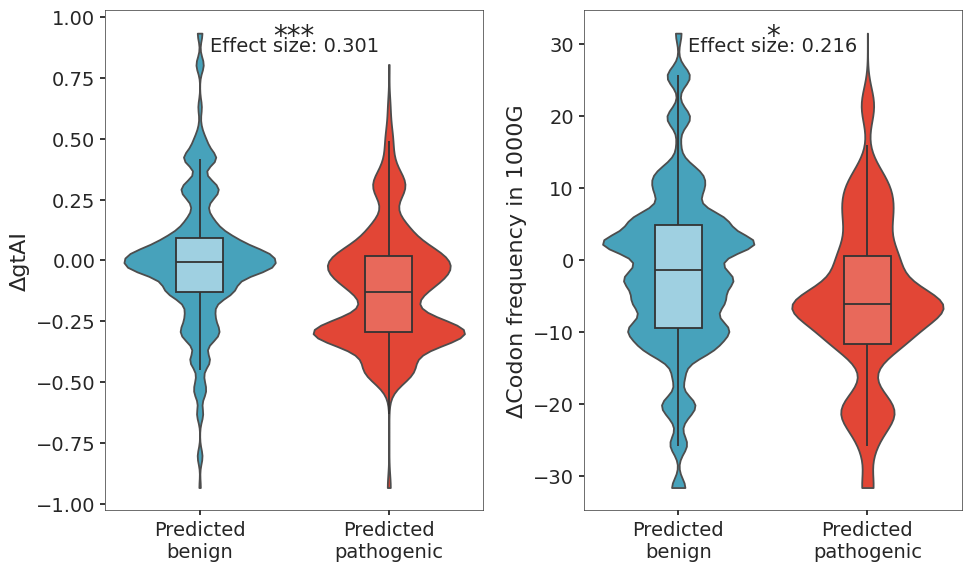

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Style settings
sns.set_style("ticks")
plt.rcParams.update({
    "font.size": 16,
    "axes.linewidth": 1.3,
    "xtick.major.width": 1.3,
    "ytick.major.width": 1.3,
})
palette_deep = {
    "pathogenic": "#e24636",
    "benign": "#47a2bb"
}
palette_light = {
    "pathogenic": "#ff5644",
    "benign": "#94d5ec"
}

fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=False)

# Plotting
for ax, col, title in zip(
    axes,
    ["delta_gtai", "delta_fr"],
    ["ΔgtAI", "ΔCodon frequency in 1000G"]
):
    sns.violinplot(
        data=plot_df,
        x="label",
        y=col,
        palette=palette_deep,
        inner=None,                 # Do not use seaborn's built-in box
        linewidth=1.3,
        saturation=1.0,
        cut=0,
        scale="width",
        color=None,
        ax=ax
    )
    sns.boxplot(
        data=plot_df,
        x="label",
        palette=palette_light,
        y=col,
        width=0.25,                
        showcaps=False,
        showfliers=False,
        boxprops=dict(
            edgecolor="#333",
            linewidth=1.3
        ),
        medianprops=dict(color="#333", linewidth=1.3),
        whiskerprops=dict(color="#333", linewidth=1.3),
        capprops=dict(color="#333", linewidth=1.3),
        ax=ax
    )
    ax.set_xlabel("")
    ax.set_ylabel(title, fontsize=16)
    ax.tick_params(axis='both', labelsize=14)
    
    # Significance annotation
    p = stats_df[stats_df['attribute'] == col].iloc[0]['p_value']
    effect_size = round(stats_df[stats_df['attribute'] == col].iloc[0]['effect_size'], 3)
    label = "ns" if p >= 0.05 else ("*" if p < 0.05 else "**" if p < 0.01 else "***")
    y_max = plot_df[col].max() 
    ax.text(0.5, y_max * 0.95, label, ha="center", fontsize=20)
    ax.text(0.5, y_max * 0.92, f'\nEffect size: {effect_size}', ha="center", fontsize=14)

    # Enforce all borders
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)
        spine.set_color("#333")
    
    # Wrap text for display
    ax.set_xticklabels([
        "Predicted\nbenign",
        "Predicted\npathogenic"
    ])

plt.tight_layout()
plt.show()

### (C) Statistical-Gene level

1. Delta = P(transition | pathogenic, gene) − P(transition | benign, gene), which measures the difference between pathogenic codon transition and benign codon transition in the context of a given gene.

|Delta| Interpretation |
|---|---|
|>0| The transition is more enriched in pathogenic compared to benign |
|<0| The transition is more common in benign |
|=0| The proportion of the transition is similar in both classes, with no significant association |

2. heterogeneity = |delta1| + |delta2| + |delta3|

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D

# 0. Data preparation
df = plot_df.copy()
# Filter out genes with too few samples
gene_count = df["gene"].value_counts()
valid_genes = gene_count[gene_count >= 30].index
df = df[df["gene"].isin(valid_genes)].copy()

# 1. Calculate gene-level transition distribution
gene_dist = (
    df.groupby(
        ["gene", "label", "codon_preferred_transition"]
    )
    .size()
    .reset_index(name="count")
)
# Normalize within each gene and each label
gene_dist["prop"] = (
    gene_dist.groupby(["gene", "label"])["count"]
    .transform(lambda x: x / x.sum())
)

# 2. Pivot -> calculate delta
pivot = gene_dist.pivot_table(
    index=["gene", "codon_preferred_transition"],
    columns="label",
    values="prop",
    fill_value=0
).reset_index()
# Ensure columns exist
for col in ["benign", "pathogenic"]:
    if col not in pivot.columns:
        pivot[col] = 0

# delta
# pathogenic proportion - benign proportion
pivot["delta"] = (
    pivot["pathogenic"] - pivot["benign"]
)

# 3. Heterogeneity score
gene_score = (
    pivot.groupby("gene")["delta"]
    .apply(lambda x: np.abs(x).sum())
    .reset_index(name="heterogeneity")
)

# 4. Statistical test (2×3 chi-square)
def gene_test(g):
    table = pd.crosstab(
        g["label"],
        g["codon_preferred_transition"]
    )
    # Need at least 2x2
    if table.shape[0] < 2 or table.shape[1] < 2:
        return pd.Series({
            "pvalue": 1.0,
            "chi2": 0
        })
    chi2, p, _, _ = chi2_contingency(table)
    return pd.Series({
        "pvalue": p,
        "chi2": chi2
    })

gene_p = (
    df.groupby("gene")
    .apply(gene_test)
    .reset_index()
)

# 5. FDR correction
gene_p["fdr"] = multipletests(
    gene_p["pvalue"],
    method="fdr_bh"
)[1]

# 6. Merge
gene_score = gene_score.merge(
    gene_p,
    on="gene"
)

# 7. Calculate gene sample size
gene_n = (
    df.groupby("gene")
    .size()
    .reset_index(name="n")
)

gene_score = gene_score.merge(
    gene_n,
    on="gene"
)

# 8. Volcano-like plot
gene_score["neglog10p"] = -np.log10(
    gene_score["pvalue"] + 1e-300
)

### (D) Plot-gene level-volcano

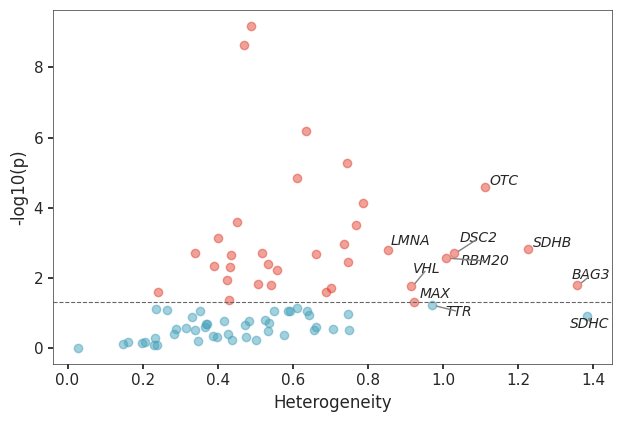

In [ ]:
from adjustText import adjust_text
import matplotlib.pyplot as plt

plt.figure(figsize=(6.5, 4.5))

# Heterogeneity + significance
significant = gene_score["neglog10p"] >= -np.log10(0.05)
non_significant = ~significant

# Plot significant points
plt.scatter(
    gene_score.loc[significant, "heterogeneity"],
    gene_score.loc[significant, "neglog10p"],
    alpha=0.5,
    color="#e24636"  # Color for significant
)

# Plot non-significant points
plt.scatter(
    gene_score.loc[non_significant, "heterogeneity"],
    gene_score.loc[non_significant, "neglog10p"],
    alpha=0.5,
    color="#47a2bb"  # Color for non-significant
)

# Significance baseline
plt.axhline(
    -np.log10(0.05),
    linestyle="--",
    linewidth=0.8,
    color="#666"
)

# Annotate the most extreme genes
extreme = gene_score.nlargest(10, "heterogeneity")
texts = []
for _, r in extreme.iterrows():
    texts.append(
        plt.text(r["heterogeneity"] + 0.005, 
                 r["neglog10p"], 
                 r["gene"], 
                 fontsize=10, 
                 fontstyle='italic')
    )

adjust_text(
    texts,
    arrowprops=dict(arrowstyle='-', color='gray', lw=1),
    expand_text=(1.2, 1.2),
    expand_points=(1.2, 1.2)
)

# Set x and y axes
plt.xlabel("Heterogeneity", fontsize=12)
plt.ylabel("-log10(p)", fontsize=12)
plt.tick_params(axis='both', labelsize=11)

# Set border thickness
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(.5)
    spine.set_color('#333')

plt.tight_layout()
plt.show()

### (D) Plot-gene level-bar

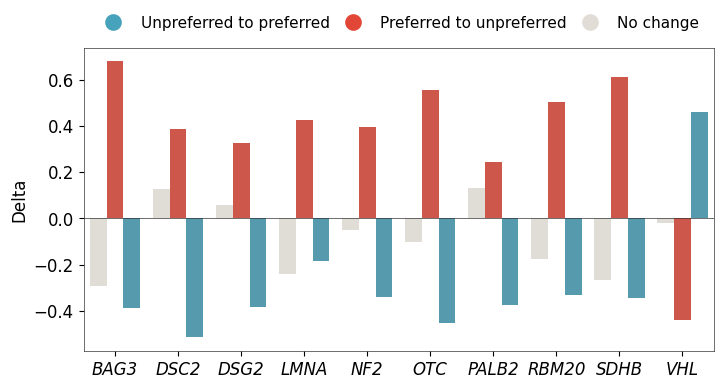

In [ ]:
# Select top genes for delta interpretation
top_gene_df = (
    gene_score
    .query("fdr < 0.05")
    .sort_values(
        "heterogeneity",
        ascending=False
    )
    .head(10)
)

top_genes = top_gene_df["gene"]

sub = pivot[
    pivot["gene"].isin(top_genes)
].copy()

# delta barplot
palette = {
    "unpreferred_to_preferred": "#47a2bb",
    "preferred_to_unpreferred": "#e24636",
    "no_change": "#e1ddd6"
}

plt.figure(figsize=(7.5, 4))
sns.barplot(
    data=sub,
    x="gene",
    y="delta",
    hue="codon_preferred_transition",
    palette=palette
)

# legend
markersize = 12
legend_elements = [
    Line2D(
        [0], [0],
        marker='o',
        linestyle='none',
        color='none',
        label='Unpreferred to preferred',
        markerfacecolor=palette[
            "unpreferred_to_preferred"
        ],
        markeredgecolor='None',
        markersize=markersize
    ),
    Line2D(
        [0], [0],
        marker='o',
        linestyle='none',
        color='none',
        label='Preferred to unpreferred',
        markerfacecolor=palette[
            "preferred_to_unpreferred"
        ],
        markeredgecolor='None',
        markersize=markersize
    ),
    Line2D(
        [0], [0],
        marker='o',
        linestyle='none',
        color='none',
        label='No change',
        markerfacecolor=palette[
            "no_change"
        ],
        markeredgecolor='None',
        markersize=markersize
    )
]
plt.legend(
    handles=legend_elements,
    frameon=False,
    fontsize=11,
    ncol=3,
    loc='upper center',
    bbox_to_anchor=[0.5, 1.15],
    labelspacing=0.5,
    columnspacing=0.5,
)

# axis
plt.xlabel("")
plt.ylabel("Delta", fontsize=12)
plt.tick_params(axis='both', labelsize=12)
plt.axhline(
    0,
    linestyle="-",
    linewidth=.5,
    color="#333"
)

plt.xticks(
    rotation=0,
    fontstyle='italic'
)

# border
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(0.5)
    spine.set_color('#333')

plt.tight_layout()
plt.show()

## Figure 5H

### (A) Statistic-global level

In [ ]:
import pandas as pd
import numpy as np

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

import seaborn as sns
import matplotlib.pyplot as plt

# 1. Import data
def classify(p):
    """Map categories based on score"""
    if p >= 0.9:
        return 'pathogenic'
    elif p <= 0.1:
        return 'benign'
    else:
        return 'indeterminate'

def cliffs_delta(x, y):
    """
    # If delta > 0: benign group has higher values than pathogenic group
    # If delta < 0: pathogenic group has higher values than benign group
    # Larger |delta| indicates more pronounced difference between the two groups
    """
    x = np.array(x)
    y = np.array(y)
    if len(x) == 0 or len(y) == 0:
        return np.nan
    return (np.sum(x[:, None] > y) - np.sum(x[:, None] < y)) / (len(x) * len(y))

df = pd.read_csv(
    "./result/Section5/ACMG.actionable.genes.GRCh38.vcf",
    sep='\t'
)

df = df.copy()

df['label'] = df['pred_prob'].apply(classify)

# 2. Keep only pathogenic / benign
df = df[
    df['label'].isin(['pathogenic', 'benign'])
].copy()

# 3. SpliceAI attributes to analyze
splice_cols = [
    'SpliceAI_acc_gain',
    'SpliceAI_acc_loss',
    'SpliceAI_don_gain',
    'SpliceAI_don_loss'
]

# 4. Convert data to numeric (avoid strings)
for col in splice_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 5. Mann-Whitney U test
stats_results = []
for col in splice_cols:
    benign = df.loc[
        df['label'] == 'benign',
        col
    ].dropna()
    pathogenic = df.loc[
        df['label'] == 'pathogenic',
        col
    ].dropna()

    n1 = len(benign)
    n2 = len(pathogenic)

    # Mann-Whitney U
    stat, p = mannwhitneyu(
        benign,
        pathogenic,
        alternative='two-sided'
    )

    effect_size = cliffs_delta(benign, pathogenic)
    stats_results.append({
        "feature": col,
        "U_statistic": stat,
        "pvalue": p,
        "effect_size": effect_size,
        "benign_mean": benign.mean(),
        "pathogenic_mean": pathogenic.mean(),
        "benign_median": benign.median(),
        "pathogenic_median": pathogenic.median(),
        "n_benign": n1,
        "n_pathogenic": n2,
    })

stats_df = pd.DataFrame(stats_results)

# 6. FDR correction
stats_df["fdr"] = multipletests(
    stats_df["pvalue"],
    method="fdr_bh"
)[1]

# 7. Output statistical results
print("\n=== Mann-Whitney U test ===")
display(
    stats_df.sort_values("pvalue")
)

/tmp/ipykernel_3136613/3339742584.py:32: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(



=== Mann-Whitney U test ===


,feature,U_statistic,pvalue,effect_size,benign_mean,pathogenic_mean,benign_median,pathogenic_median,n_benign,n_pathogenic,fdr
3,SpliceAI_don_loss,22824648.5,0.000000e+00,-0.590491,0.001194,0.205767,0.0,0.03,53930,2067,0.000000e+00
2,SpliceAI_don_gain,21790644.0,0.000000e+00,-0.609043,0.002397,0.286647,0.0,0.07,53930,2067,0.000000e+00
1,SpliceAI_acc_loss,50832991.0,1.347195e-182,-0.087979,0.000360,0.018520,0.0,0.00,53930,2067,1.796260e-182
0,SpliceAI_acc_gain,51044731.0,3.075282e-34,-0.084180,0.002848,0.069632,0.0,0.00,53930,2067,3.075282e-34


### (B) Plot-global level

/tmp/ipykernel_3136613/119919078.py:48: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  leg = plt.legend(


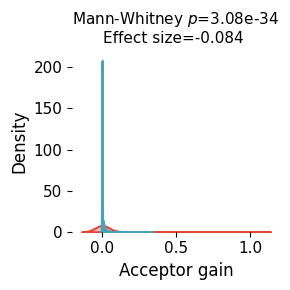

/tmp/ipykernel_3136613/119919078.py:48: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  leg = plt.legend(


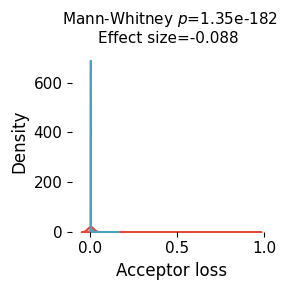

/tmp/ipykernel_3136613/119919078.py:48: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  leg = plt.legend(


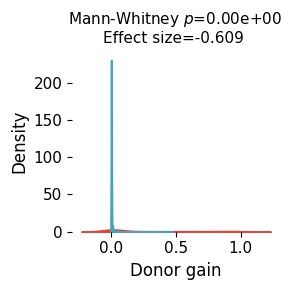

/tmp/ipykernel_3136613/119919078.py:48: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  leg = plt.legend(


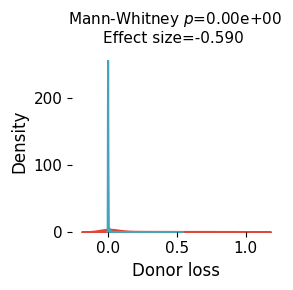

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# configs
palette = {
    "benign": "#47a2bb",
    "pathogenic": "#e24636"
}
mapping = {
    'Acceptor gain': 'SpliceAI_acc_gain',
    'Acceptor loss': 'SpliceAI_acc_loss',
    'Donor gain': 'SpliceAI_don_gain',
    'Donor loss': 'SpliceAI_don_loss'
}

for k, v in mapping.items():
    plt.figure(figsize=(3, 3))
    sns.kdeplot(
        data=df,
        x=v,
        hue="label",
        fill=True,
        common_norm=False,
        alpha=0.35,
        linewidth=1.5,
        palette=palette
    )
    # Add statistical information
    row = stats_df[
        stats_df["feature"] == v
    ].iloc[0]
    # rbc_text = f"RBC={row['RBC']:.3f}"
    rbc_text = f"Effect size={row['effect_size']:.3f}"
    plt.title(
        f"Mann-Whitney $p$={row['pvalue']:.2e} \n{rbc_text} ",
        fontsize=11
    )

    # axis
    plt.xlabel(k, fontsize=12)
    plt.ylabel("Density", fontsize=12)
    plt.tick_params(
        axis='both',
        labelsize=11
    )

    # legend
    leg = plt.legend(
        frameon=False,
        fontsize=10
    )

    # border
    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_visible(False)
    plt.tight_layout()
    plt.show()

### (C) Statistic-gene level

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt


def cliffs_delta(x, y):
    """
    # If delta > 0: pathogenic group has higher Splice score than benign group
    # If delta < 0: benign group has higher value than pathogenic group
    # Larger |delta| indicates more pronounced difference between the two groups
    """
    x = np.array(x)
    y = np.array(y)
    if len(x) == 0 or len(y) == 0:
        return np.nan
    return (np.sum(x[:, None] > y) - np.sum(x[:, None] < y)) / (len(x) * len(y))

# 1. Import data
def classify(p):
    if p >= 0.9:
        return 'pathogenic'
    elif p <= 0.1:
        return 'benign'
    else:
        return 'indeterminate'
    
df = pd.read_csv("./result/Section5/ACMG.actionable.genes.GRCh38.vcf", sep='\t')
df = df.copy()
df['label'] = df['pred_prob'].apply(classify)

# 2. Keep only pathogenic / benign
df = df[
    df['label'].isin([
        'pathogenic',
        'benign'
    ])
].copy()

# 3. SpliceAI columns
splice_cols = [
    'SpliceAI_acc_gain',
    'SpliceAI_acc_loss',
    'SpliceAI_don_gain',
    'SpliceAI_don_loss'
]
# Convert to numeric
for col in splice_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors='coerce'
    )
    
# 4. Gene-level analysis
all_results = []
for col in splice_cols:
    # Analyze each gene separately
    for gene, g in df.groupby("gene"):
        benign = g.loc[
            g["label"] == "benign",
            col
        ].dropna()
        pathogenic = g.loc[
            g["label"] == "pathogenic",
            col
        ].dropna()
        # Ensure at least some samples
        if (
            len(benign) < 5 or
            len(pathogenic) < 5
        ):
            continue
        # Mann-Whitney U
        stat, p = mannwhitneyu(
            benign,
            pathogenic,
            alternative='two-sided'
        )
        n1 = len(benign)
        n2 = len(pathogenic)

        # Cliff's delta
        cd = cliffs_delta(pathogenic, benign)

        all_results.append({
            "feature": col,
            "gene": gene,
            "pvalue": p,
            "U": stat,
            "CD": cd,
            "n_benign": n1,
            "n_pathogenic": n2
        })

results_df = pd.DataFrame(all_results)

# 5. FDR correction
results_df["fdr"] = np.nan
for col in splice_cols:
    mask = results_df["feature"] == col
    results_df.loc[mask, "fdr"] = multipletests(
        results_df.loc[mask, "pvalue"],
        method='fdr_bh'
    )[1]

### (D) Plot-gene level

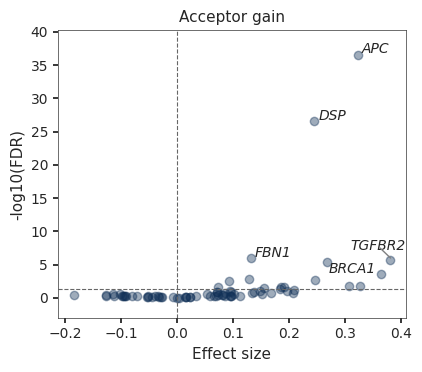

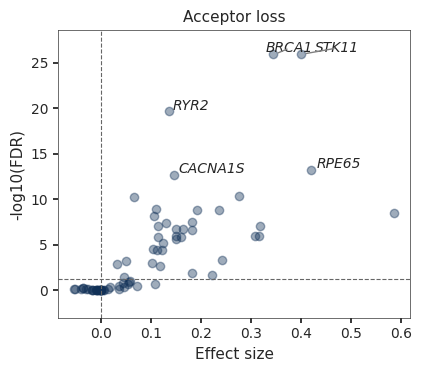

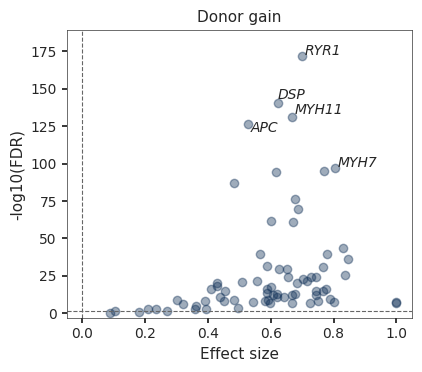

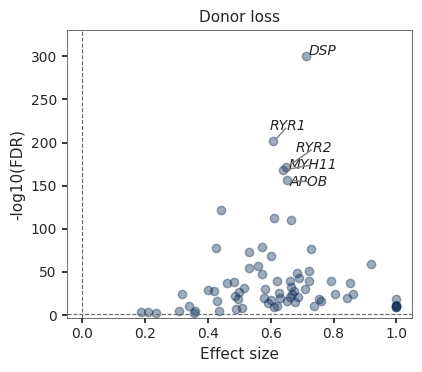

In [ ]:
from adjustText import adjust_text
import matplotlib.pyplot as plt

# 6. volcano-like plots
mapping = {
	'SpliceAI_acc_gain': 'Acceptor gain',
	'SpliceAI_acc_loss': 'Acceptor loss',
	'SpliceAI_don_gain': 'Donor gain',
	'SpliceAI_don_loss': 'Donor loss'
}

for col in splice_cols:
	sub = results_df[
		results_df["feature"] == col
	].copy()
	sub["neglog10fdr"] = -np.log10(
		sub["fdr"] + 1e-300
	)
	plt.figure(figsize=(4.5, 4))

	# scatter
	plt.scatter(
		# sub["RBC"],
		sub["CD"],
		sub["neglog10fdr"],
		alpha=0.4,
		color="#103057"
	)

	# significance threshold
	plt.axhline(
		-np.log10(0.05),
		linestyle='--',
		linewidth=0.8,
		color="#666"
	)

	# effect direction baseline
	plt.axvline(
		0,
		linestyle='--',
		linewidth=0.8,
		color="#666"
	)

	# anno top genes
	extreme = (
		sub
		.query("fdr < 0.05")
		.sort_values(
			"neglog10fdr",
			ascending=False
		)
		.head(5)
	)

	texts = []
	for _, r in extreme.iterrows():
		texts.append(plt.text(
			r["CD"] + 0.005,
			r["neglog10fdr"],
			r["gene"],
			fontsize=10,
			fontstyle='italic'
		))
	adjust_text(
		texts,
		arrowprops=dict(arrowstyle='-', color='gray', lw=1),
		expand_text=(1.2, 1.2),
		expand_points=(1.2, 1.2)
	)
	# axis
	# plt.xlabel("RBC", fontsize=11)
	plt.xlabel("Effect size", fontsize=11)
	plt.ylabel("-log10(FDR)",  fontsize=11)
	plt.title(mapping[col], fontsize=11)
	plt.tick_params(axis='both', labelsize=10)
	plt.ylim(-3, sub["neglog10fdr"].max()*1.1)

	# border
	ax = plt.gca()
	for spine in ax.spines.values():
		spine.set_linewidth(.5)
		spine.set_color('#333')
	plt.tight_layout()
	plt.show()

## 3.6 prioritization

In [ ]:
df[df['label'] == 'pathogenic'].to_csv("./result/section_5/2067.pathogenic.txt", sep='\t', index=False)

### (A) ClinVar - VUS

In [ ]:
import pandas as pd

pathogenic_df = pd.read_csv("./result/section_5/Section5/2067.pathogenic.txt", sep='\t')
clinvar_df = pd.read_csv("./result/section_5/Anno_2067/ClinVar.csv")
vus_df = clinvar_df[clinvar_df['CLNSIG'] == 'Uncertain significance']

In [50]:
subset = pathogenic_df[pathogenic_df['Variant38'].isin(vus_df['Variant38'])].sort_values(by='pred_prob', ascending=False)

In [ ]:
subset.to_csv("./result/section_5/283.VUS.pathogenic.csv", index=False)

### (B) ClinGen

1. Download: https://search.clinicalgenome.org/kb/downloads#section_gene-disease-validity
2. Filter:  CLASSIFICATION == 'Definitive'

In [ ]:
import pandas as pd
clingen_df = pd.read_csv("./result/section_5/Clingen-Gene-Disease-Summary-2026-05-07.csv")
clingen_df = clingen_df[clingen_df['CLASSIFICATION'] == 'Definitive']
clingen_df = clingen_df[['GENE SYMBOL', 'DISEASE LABEL', 'DISEASE ID (MONDO)', 'MOI']]
clingen_df.columns = ['gene', 'disease', 'mondo_id', 'moi']

def format_disease_info(group):
    """Format each row as disease=xxx,mondo_id=xxx,moi=xxx and join with |"""
    formatted_records = []
    for _, row in group.iterrows():
        record = f"disease={row['disease']},mondo_id={row['mondo_id']},moi={row['moi']}"
        formatted_records.append(record)
    return '|'.join(formatted_records)

clingen_merged = clingen_df.groupby('gene').apply(format_disease_info).reset_index()
clingen_merged.columns = ['gene', 'disease_info']
clingen_merged.to_csv("./result/section_5/Clingen-definitive.csv", index=False)
clingen_merged.head()

### (A) Splice path

In [ ]:
import pandas as pd

df = pd.read_csv("./result/section_5/283.VUS.pathogenic.csv")
df = df.sort_values(by='pred_prob', ascending=False)

# Collect the first 10 records
count = 0
records = []
for idx, row in df.iterrows():
    if row['SpliceAI_don_gain'] > 0.9 or row['SpliceAI_don_loss'] > 0.9:
        records.append(row)
        count += 1
        if count >= 10:
            break

# Save top 10
result_df = pd.DataFrame(records)
usecols = ['Variant38', 'TranSyn_score', 'gene', 'SpliceAI_don_gain', 'SpliceAI_don_loss']
result_df.rename(columns={'pred_prob': 'TranSyn_score'}, inplace=True)
result_df = result_df[usecols]
result_df = result_df.merge(clingen_merged, how='left', left_on='gene', right_on='gene', suffixes=('', '_m'))
result_df.head()
result_df.to_csv("./result/section_5/top10_splice_high_confidence.csv", index=False)

### (B) mRNA path

In [ ]:
import pandas as pd

count = 0
records = []
for idx, row in df.iterrows():
    if abs(row['delta_MFE'])>4:
        count += 1
        records.append(row)
        if count >= 11:
            break

# save top 10
result_df = pd.DataFrame(records)
usecols = ['Variant38', 'TranSyn_score', 'gene', 'delta_MFE']
result_df.rename(columns={'pred_prob': 'TranSyn_score'}, inplace=True)
result_df = result_df[usecols]
result_df = result_df.merge(clingen_merged, how='left', left_on='gene', right_on='gene', suffixes=('', '_m'))
result_df.head()
result_df.to_csv("./result/Section5/top10_mRNA_structure_high_confidence.csv", index=False)

### (C) CUB path

In [ ]:
import pandas as pd

df = pd.read_csv("./result/section_5/283.VUS.pathogenic.csv")
df = df.sort_values(by='pred_prob', ascending=False)

# Collect the first 10 records
count = 0
records = []
for idx, row in df.iterrows():
    if (row['delta_gtai'] < -0.9) or (row['delta_fr'] < -30):
        # print(row)
        # print("\n")
        records.append(row)
        count += 1
        if count >= 10:
            break

# save top 10
result_df = pd.DataFrame(records)
usecols = ['Variant38', 'TranSyn_score', 'gene', 'delta_gtai', 'delta_fr']
result_df.rename(columns={'pred_prob': 'TranSyn_score'}, inplace=True)
result_df = result_df[usecols]
result_df = result_df.merge(clingen_merged, how='left', left_on='gene', right_on='gene', suffixes=('', '_m'))
result_df.head()
result_df.to_csv("./result/section_5/top10_cub_high_confidence.csv", index=False)